# Embedded Renewable Generation Analysis in Great Britain (2024)

This notebook investigates patterns in embedded wind and solar generation using the 2024 Historic Demand Data published by the National Energy System Operator (NESO).

The analysis examines typical daily generation profiles and explores the relationship between embedded renewable generation and National Demand (ND).

**Scope:** The dataset contains estimates of embedded wind and solar generation. These variables do not represent total wind and solar electricity generation in Great Britain.

### Analysis Workflow

1. Import the required libraries and load the dataset.
2. Examine summary statistics for embedded wind and solar generation.
3. Analyse typical daily solar generation patterns.
4. Analyse typical daily wind generation patterns.
5. Investigate correlations between embedded renewable generation and National Demand.
6. Visualise relationships using scatter plots.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the Dataset

The 2024 NESO Historic Demand Data is loaded from the project's raw data directory into a pandas DataFrame for analysis.

In [14]:
df = pd.read_csv("../data/raw/demanddata_2024.csv")

In [15]:
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,01-JAN-2024,1,21783,23466,19539,2804,6488,0,16793,0,...,417,-4,666,-179,-92,905,62,998,572,0
1,01-JAN-2024,2,22521,24103,20286,2834,6488,0,16793,0,...,430,-4,661,-60,-8,901,-15,998,575,0
2,01-JAN-2024,3,22194,24754,20070,2868,6488,0,16793,0,...,834,-4,661,-118,-1,807,-396,997,422,0
3,01-JAN-2024,4,21510,24505,19424,2901,6488,0,16793,0,...,839,-4,661,-270,-84,803,-473,997,401,0
4,01-JAN-2024,5,20619,23977,18674,2933,6488,0,16793,0,...,53,-5,661,-340,-103,537,-856,998,28,0


In [16]:
df["SETTLEMENT_DATE"] = pd.to_datetime(
    df["SETTLEMENT_DATE"],
    format="%d-%b-%Y"
)

## 2. Renewable Generation Analysis

This section explores patterns in embedded wind and solar generation and examines their relationship with National Demand (ND).

The renewable generation variables in this dataset represent estimated embedded generation and therefore do not capture all wind and solar electricity generation in Great Britain.

In [17]:
renewable_summary = df[
    ["EMBEDDED_WIND_GENERATION", "EMBEDDED_SOLAR_GENERATION"]
].describe()

renewable_summary

,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION
count,17568.000000,17568.000000
mean,1932.204918,1588.168545
std,1266.052754,2468.029143
min,229.000000,0.000000
25%,922.000000,0.000000
50%,1601.000000,3.000000
75%,2687.000000,2542.000000
max,5962.000000,11498.000000


### Typical Daily Solar Generation Profile

Average embedded solar generation is examined across settlement periods to understand how solar output varies throughout a typical day.

In [18]:
solar_daily_profile = (
    df.groupby("SETTLEMENT_PERIOD")["EMBEDDED_SOLAR_GENERATION"]
    .mean()
)

solar_daily_profile

SETTLEMENT_PERIOD
1        0.000000
2        0.000000
3        0.000000
4        0.000000
5        0.000000
6        0.000000
7        0.000000
8        0.000000
9        0.000000
10       0.002732
11       6.404372
12      46.530055
13     143.557377
14     325.568306
15     606.685792
16     991.573770
17    1489.363388
18    2085.106557
19    2737.628415
20    3376.278689
21    3938.379781
22    4411.923497
23    4770.685792
24    5028.338798
25    5174.653005
26    5157.721311
27    5060.822404
28    4844.521858
29    4540.213115
30    4162.631148
31    3694.051913
32    3204.639344
33    2722.969945
34    2239.081967
35    1770.554645
36    1338.991803
37     975.237705
38     663.396175
39     404.180328
40     211.431694
41      86.571038
42      21.122951
43       1.270492
44       0.000000
45       0.000000
46       0.000000
47       0.000000
48       0.000000
49       0.000000
50       0.000000
Name: EMBEDDED_SOLAR_GENERATION, dtype: float64

**Note on settlement periods:** A standard day contains 48 half-hour settlement periods. Due to UK daylight-saving time changes, 31 March 2024 contains 46 settlement periods, while 27 October 2024 contains 50. For the typical daily profile analysis, settlement periods 1–48 are used to maintain a consistent daily structure and prevent the additional DST periods (49 and 50), which occur only once in the dataset, from distorting the average profiles. The original observations are retained in the dataset.

In [19]:
solar_daily_profile_normal = solar_daily_profile[
    solar_daily_profile.index <= 48
]

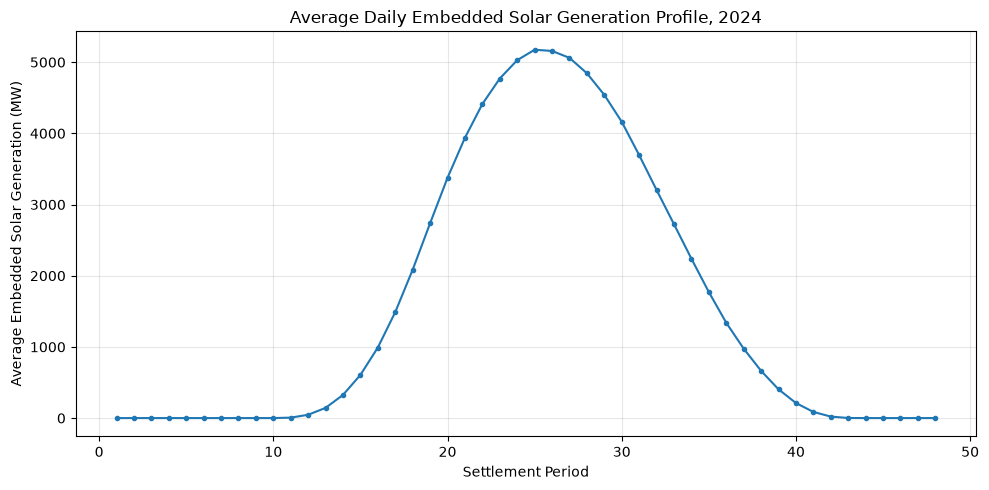

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    solar_daily_profile_normal.index,
    solar_daily_profile_normal.values,
    marker="o",
    markersize=3
)

plt.title("Average Daily Embedded Solar Generation Profile, 2024")
plt.xlabel("Settlement Period")
plt.ylabel("Average Embedded Solar Generation (MW)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
solar_peak_period = solar_daily_profile_normal.idxmax()
solar_peak_generation = solar_daily_profile_normal.max()

solar_peak_period, solar_peak_generation

(np.int64(25), np.float64(5174.653005464481))

**Finding:** Embedded solar generation follows a clear daily pattern. Average generation is close to zero overnight, begins increasing during the early morning, and reaches a peak of approximately 5,175 MW at settlement period 25 (around midday). Generation then declines through the afternoon and returns towards zero during the evening. The profile is approximately symmetric around the midday peak.

### Typical Daily Wind Generation Profile

Average embedded wind generation is examined across settlement periods to understand how wind output varies throughout a typical day.

As with the solar daily profile, the analysis is restricted to the standard 48 settlement periods. Settlement periods 49 and 50 are excluded because they occur only on the daylight-saving transition day and are not representative of a typical daily profile.

In [22]:
wind_daily_profile = (
    df.groupby("SETTLEMENT_PERIOD")["EMBEDDED_WIND_GENERATION"]
    .mean()
)

In [23]:
wind_daily_profile_normal = wind_daily_profile[
    wind_daily_profile.index <= 48
]

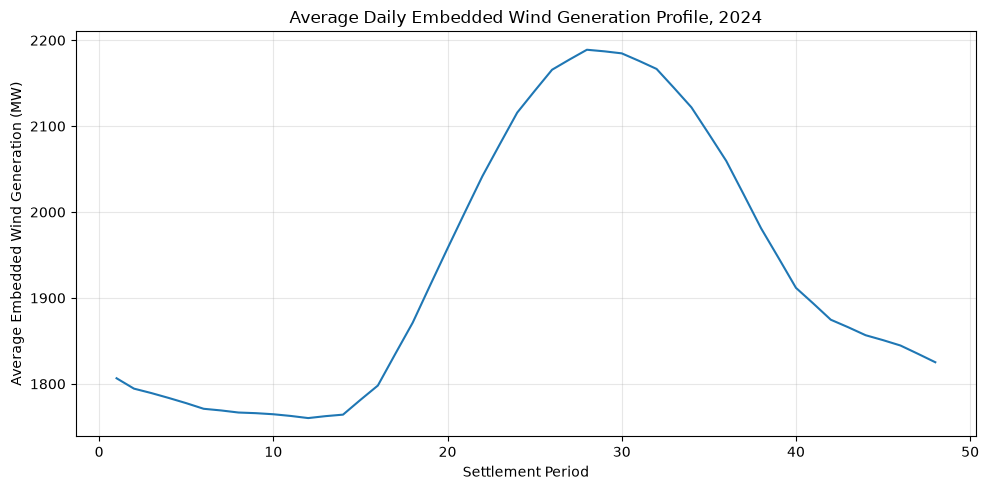

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    wind_daily_profile_normal.index,
    wind_daily_profile_normal.values
)

plt.title("Average Daily Embedded Wind Generation Profile, 2024")
plt.xlabel("Settlement Period")
plt.ylabel("Average Embedded Wind Generation (MW)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
wind_peak_period = wind_daily_profile_normal.idxmax()
wind_peak_generation = wind_daily_profile_normal.max()

wind_peak_period, wind_peak_generation

(np.int64(28), np.float64(2188.9262295081967))

**Finding:** Embedded wind generation shows a less pronounced daily pattern than solar generation. Average wind generation declines slightly during the early part of the day before increasing from around settlement period 14 and reaching a peak of approximately 2,189 MW at settlement period 28 (around 13:30). Generation then generally declines through the remainder of the day. Unlike solar generation, wind output remains present throughout the full daily cycle and does not show the strong day-night pattern observed for solar.

### Relationship Between Renewable Generation and Electricity Demand

The relationship between National Demand (ND) and embedded wind and solar generation is examined to determine whether changes in renewable generation are associated with changes in electricity demand.

In [26]:
renewable_correlation = df[
    [
        "ND",
        "EMBEDDED_WIND_GENERATION",
        "EMBEDDED_SOLAR_GENERATION"
    ]
].corr()

renewable_correlation

,ND,EMBEDDED_WIND_GENERATION,EMBEDDED_SOLAR_GENERATION
ND,1.000000,0.051672,-0.131763
EMBEDDED_WIND_GENERATION,0.051672,1.000000,-0.005965
EMBEDDED_SOLAR_GENERATION,-0.131763,-0.005965,1.000000


**Finding:** National Demand shows very little linear relationship with embedded wind generation, with a correlation coefficient of approximately **0.052**. Embedded solar generation has a weak negative correlation with National Demand of approximately **−0.132**, indicating that periods of higher solar generation tend to be associated with slightly lower National Demand.

These correlations are weak and should not be interpreted as evidence of causation. Electricity demand and renewable generation are both influenced by other factors, including time of day and seasonal conditions.

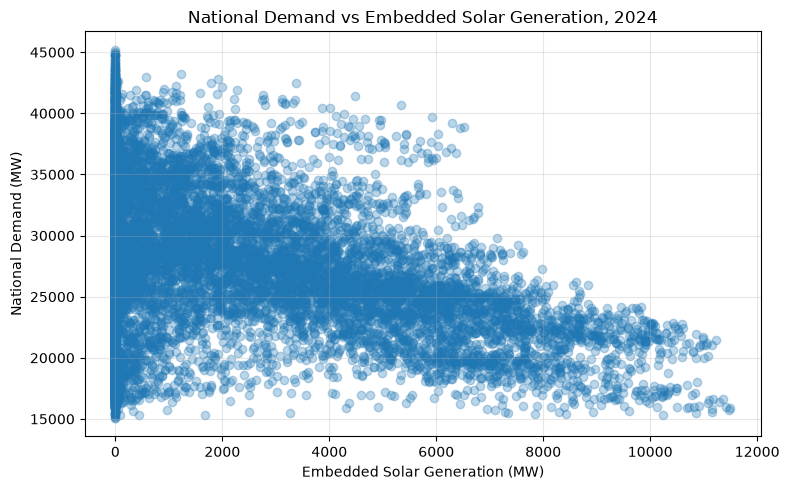

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["EMBEDDED_SOLAR_GENERATION"],
    df["ND"],
    alpha=0.3
)

plt.title("National Demand vs Embedded Solar Generation, 2024")
plt.xlabel("Embedded Solar Generation (MW)")
plt.ylabel("National Demand (MW)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** The scatter plot shows a slight downward relationship between embedded solar generation and National Demand, consistent with the weak negative correlation of approximately −0.132. However, the observations are widely dispersed, indicating that solar generation alone does not strongly explain variations in electricity demand. Other factors, including time of day and season, are likely to influence the observed relationship.

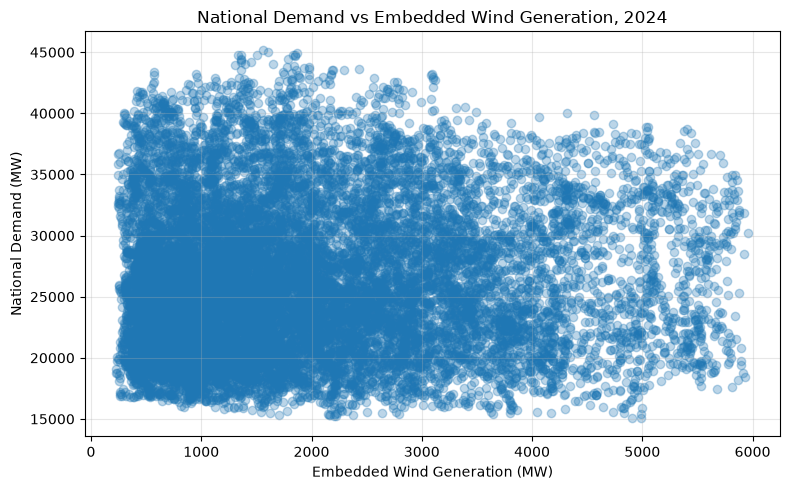

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["EMBEDDED_WIND_GENERATION"],
    df["ND"],
    alpha=0.3
)

plt.title("National Demand vs Embedded Wind Generation, 2024")
plt.xlabel("Embedded Wind Generation (MW)")
plt.ylabel("National Demand (MW)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** The scatter plot shows no clear relationship between embedded wind generation and National Demand. The observations are widely dispersed with no meaningful upward or downward trend, consistent with the very weak positive correlation of approximately 0.052. This suggests that variations in embedded wind generation have little linear association with variations in National Demand over the period analysed.

## 3. Key Findings and Conclusions

The analysis revealed distinct daily generation patterns for embedded solar and wind generation in Great Britain during 2024.

Embedded solar generation followed a pronounced daytime cycle, reaching its highest average output around midday. Embedded wind generation showed a less pronounced daily pattern, with output present throughout the day.

The correlation analysis found very weak linear relationships between embedded renewable generation and National Demand. Embedded wind generation had a correlation coefficient of approximately 0.052, while embedded solar generation had a weak negative correlation of approximately −0.132.

These findings suggest that simple linear correlations are insufficient to explain the relationship between electricity demand and embedded renewable generation. Time of day, seasonality and weather conditions may influence the observed patterns.

**Limitations:** The dataset captures estimated embedded wind and solar generation rather than total renewable generation in Great Britain. The analysis also covers only one year and does not control for weather, seasonal effects or other potentially influential factors.